# General-Purpose Data Inspection & Cleaning Template

This notebook is a reusable checklist for **any** new dataset, worked through using `transaction.csv` (the practice case file) as the live example. The order matters: each step exists because skipping it lets a problem hide and corrupt a later step — most of these are exactly the kind of thing that bit us in the earlier pass at this same file (the sort-before-loop bug, the un-segmented "gradual and stable" chart).

Run top to bottom on a new dataset. Don't skip ahead to the interesting business question until the boring inspection steps are done — the inspection steps are what tell you whether your answer to the business question can be trusted.

## Step 1 — Setup

Standard imports. Using plain `matplotlib` here instead of `hvplot`/Bokeh — fewer dependencies to worry about in an unfamiliar live-test environment, and a static plot is faster to render and easier for an interviewer to read over a screen share than an interactive widget.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Step 2 — First look: shape, head/tail, dtypes

**Why:** Before any analysis, you need to know what you're actually holding — how many rows, what columns, what type each column *thinks* it is. `head()` AND `tail()`, not just `head()` — a CSV can have garbage rows at the end, or a different format that crept in partway through. This is the step that was skipped last time; everything downstream assumes you did this.

In [48]:
df = pd.read_csv('transactions_dataset.csv')
print("Shape:", df.shape)
df

Shape: (1550, 10)


,transaction_id,user_id,merchant_id,amount,status,status_reason,channel,region,is_new_user,created_at
0,100881,358,m0027,49400.0,SUCCESS,NaN,CARD,ID,False,2026-06-13T04:19:00
1,100446,114,M-0017,451300.0,SUCCESS,NaN,BANK_TRANSFER,ID,False,2026-06-05T17:29:00
2,100841,190,m-0013,12000.0,SUCCESS,NaN,BANK_TRANSFER,ID,False,2026-06-12T22:22:00
3,101023,472,M0025,397300.0,SUCCESS,NaN,QR,PH,False,2026-06-16T03:18:00
4,100661,117,m0007,76000.0,SUCCESS,NaN,CARD,VN,False,2026-06-09T15:37:00
...,...,...,...,...,...,...,...,...,...,...
1545,100212,357,M-0018,186600.0,SUCCESS,NaN,BANK_TRANSFER,VN,True,2026-05-31T07:40:00
1546,100503,41,M-0014,65600.0,SUCCESS,NaN,QR,ID,True,2026-06-06T17:03:00
1547,100538,396,M0018,52600.0,SUCCESS,NaN,BANK_TRANSFER,ID,True,2026-06-07T04:16:00
1548,101221,275,M0014,462000.0,SUCCESS,NaN,QR,TH,True,2026-06-20T23:01:00


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1550 entries, 0 to 1549
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  1550 non-null   int64  
 1   user_id         1550 non-null   int64  
 2   merchant_id     1550 non-null   str    
 3   amount          1541 non-null   float64
 4   status          1550 non-null   str    
 5   status_reason   135 non-null    str    
 6   channel         1550 non-null   str    
 7   region          1550 non-null   str    
 8   is_new_user     1550 non-null   bool   
 9   created_at      1550 non-null   str    
dtypes: bool(1), float64(1), int64(2), str(6)
memory usage: 110.6 KB


## Step 3 — Missing values

**Why:** Nulls silently break aggregations (`sum()` skips them by default, which can quietly understate a total) and crash some operations outright. You need to know *which* columns have nulls and *how much*, before deciding whether to drop, impute, or flag — that decision comes later (Step 8); this step is just measurement.

In [33]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
pd.DataFrame({'missing_count': missing_count, 'missing_pct': missing_pct}).sort_values('missing_count', ascending=False)

,missing_count,missing_pct
status_reason,1415,91.29
amount,9,0.58
user_id,0,0.00
transaction_id,0,0.00
merchant_id,0,0.00
status,0,0.00
channel,0,0.00
region,0,0.00
is_new_user,0,0.00
created_at,0,0.00


## Step 4 — Duplicate rows

**Why:** Duplicates inflate counts and sums without any error being thrown — your numbers will just be quietly wrong. Check two things separately: (1) fully identical rows (a copy-paste or pipeline error), and (2) duplicate values in whatever column *should* be unique (here, `transaction_id`) — these aren't the same check, and a dataset can fail one without failing the other.

In [34]:
print("Fully duplicate rows:", df.duplicated().sum())
print("Duplicate transaction_id (should be unique):", df.duplicated(subset=['transaction_id']).sum())

# Look at the actual duplicate rows before deciding what to do with them
df[df.duplicated(subset=['transaction_id'], keep=False)].sort_values('transaction_id').head(10)

Fully duplicate rows: 5
Duplicate transaction_id (should be unique): 5


,transaction_id,user_id,merchant_id,amount,status,status_reason,channel,region,is_new_user,created_at
882,100481,471,M0006,158900.0,SUCCESS,NaN,EWALLET,TH,False,2026-06-05T19:12:00
1056,100481,471,M0006,158900.0,SUCCESS,NaN,EWALLET,TH,False,2026-06-05T19:12:00
1458,100637,31,M0017,124100.0,SUCCESS,NaN,EWALLET,VN,False,2026-06-09T06:39:00
180,100637,31,M0017,124100.0,SUCCESS,NaN,EWALLET,VN,False,2026-06-09T06:39:00
603,101232,73,M0026,49200.0,SUCCESS,NaN,CARD,VN,True,2026-06-20T13:19:00
458,101232,73,M0026,49200.0,SUCCESS,NaN,CARD,VN,True,2026-06-20T13:19:00
329,101263,162,m0027,65700.0,FAILED,NETWORK_ERROR,BANK_TRANSFER,TH,False,2026-06-21T22:28:00
1003,101263,162,m0027,65700.0,FAILED,NETWORK_ERROR,BANK_TRANSFER,TH,False,2026-06-21T22:28:00
1048,101314,205,M0033,265000.0,SUCCESS,NaN,CARD,PH,False,2026-06-22T08:48:00
637,101314,205,M0033,265000.0,SUCCESS,NaN,CARD,PH,False,2026-06-22T08:48:00


## Step 5 — Fix data types

**Why:** `read_csv` guesses types, and it guesses wrong constantly — dates come in as plain strings, categorical columns come in as generic `object`. Nothing time-based (sorting by date, rolling windows, filtering "last 7 days") works correctly until `created_at` is an actual datetime, not a string that merely *looks* like one. Converting repeat-value columns to `category` also makes `groupby` faster and `value_counts` clearer.

In [35]:
df['created_at'] = pd.to_datetime(df['created_at'])

for col in ['status', 'status_reason', 'channel', 'region']:
    df[col] = df[col].astype('category')

df.dtypes

transaction_id             int64
user_id                    int64
merchant_id                  str
amount                   float64
status                  category
status_reason           category
channel                 category
region                  category
is_new_user                 bool
created_at        datetime64[us]
dtype: object

## Step 6 — Consistency check on text/categorical columns

**Why:** A column can have the *right* dtype (string) and still be inconsistent in *content* — different casing, stray whitespace, inconsistent separators, all referring to the same real-world entity. `nunique()` is your tripwire: if you expect ~40 distinct merchants and get 90+, that gap is exactly the size of your formatting problem. Eyeball a sample of the actual unique values to see the pattern before writing a fix.

In [36]:
print("Raw unique merchant_id values:", df['merchant_id'].nunique())
sorted(df['merchant_id'].astype(str).unique())[:15]   # eyeball a sample for the formatting pattern

Raw unique merchant_id values: 155


['M-0001',
 'M-0002',
 'M-0003',
 'M-0004',
 'M-0005',
 'M-0006',
 'M-0007',
 'M-0008',
 'M-0009',
 'M-0010',
 'M-0011',
 'M-0012',
 'M-0013',
 'M-0014',
 'M-0015']

In [37]:
def normalize_merchant_id(raw):
    if pd.isna(raw):
        return np.nan
    return str(raw).strip().upper().replace('-', '')

df['merchant_id_clean'] = df['merchant_id'].apply(normalize_merchant_id)
print("Cleaned unique merchant_id values:", df['merchant_id_clean'].nunique())
# The drop from raw to clean count tells you how many rows were affected by formatting noise

Cleaned unique merchant_id values: 39


## Step 7 — Range & sanity checks

**Why:** `describe()` catches numeric nonsense (negative amounts, a max that's 1000x the median, suspiciously round numbers everywhere). `value_counts()` on categoricals catches label nonsense (a typo'd status value, an unexpected fifth channel that shouldn't exist). This is where you find the "this number is impossible" problems, separate from the "this number is missing" problems from Step 3.

In [38]:
df['amount'].describe()

count    1.541000e+03
mean     1.603058e+05
std      1.510245e+05
min      1.070000e+04
25%      5.070000e+04
50%      1.149000e+05
75%      2.185000e+05
max      1.235900e+06
Name: amount, dtype: float64

In [39]:
print("Rows with amount <= 0:", (df['amount'] <= 0).sum())
print()
print(df['status'].value_counts())
print()
print(df['channel'].value_counts())
print()
print(df['region'].value_counts())

Rows with amount <= 0: 0

status
SUCCESS    1415
FAILED      135
Name: count, dtype: int64

channel
CARD             451
BANK_TRANSFER    370
QR               370
EWALLET          359
Name: count, dtype: int64

region
ID    423
PH    397
TH    368
VN    362
Name: count, dtype: int64


## Step 8 — Make cleaning decisions, explicitly and visibly

**Why:** Every cleaning action should be a deliberate, stated choice, not something buried silently inside a transformation — both because you need to be able to defend it live ("why did you drop those rows and not flag them?"), and because a silent drop changes the denominator for every calculation after it without leaving a trace. Prefer **flagging** over silently dropping when the impact is small enough to not distort the analysis — it keeps the row, and keeps your option to exclude it open, visible, and explained.

In [40]:
# 1. Drop exact duplicate rows (these are unambiguous data errors, safe to drop)
before = len(df)
df = df.drop_duplicates()
print(f"Dropped {before - len(df)} exact duplicate rows")

# 2. Missing amount: flag rather than silently drop, since dropping changes counts
#    used by every other calculation downstream — keep the row, note the gap.
df['amount_missing'] = df['amount'].isnull()
print(f"{df['amount_missing'].sum()} rows have missing amount — flagged, not dropped")

# 3. Adopt the cleaned merchant_id going forward
df['merchant_id'] = df['merchant_id_clean']
df = df.drop(columns=['merchant_id_clean'])

Dropped 5 exact duplicate rows
9 rows have missing amount — flagged, not dropped


## Step 9 — Sort before anything time-based

**Why — this is the exact bug from the last pass.** Any cumulative sum, rolling window, "first vs. last event," or day-over-day diff is only correct if the rows are in chronological order *at the moment you compute it*. Sort once, right after cleaning, and `reset_index(drop=True)` so the row positions match the new order — don't sort separately inside every later function and risk doing it inconsistently.

In [41]:
df = df.sort_values('created_at').reset_index(drop=True)
df[['transaction_id', 'created_at']].head()

,transaction_id,created_at
0,100020,2026-05-28 01:14:00
1,100027,2026-05-28 01:37:00
2,100037,2026-05-28 01:57:00
3,100012,2026-05-28 02:24:00
4,100024,2026-05-28 02:28:00


## Step 10 — Separate into meaningful subsets

**Why:** Once the full dataset is clean and sorted, split off the slices you'll actually reason about — e.g. successes vs. failures. Keep both the subset *and* the original `df` around (use `.copy()` so edits to one don't leak into the other) — you'll need the full `df` again as the denominator when you compute rates in Step 12.

In [42]:
success_df = df[df['status'] == 'SUCCESS'].copy()
failed_df = df[df['status'] == 'FAILED'].copy()
print(f"Success: {len(success_df)}, Failed: {len(failed_df)}")

Success: 1411, Failed: 134


## Step 11 — Group and aggregate: one dimension, then combined dimensions

**Why:** A single-dimension breakdown (just `status_reason`, or just `channel`) tells you *what* is happening on average across everything else. It will NOT reveal a problem that only exists at the *intersection* of two dimensions — that requires grouping by both together. This is the step that was missing last time: separate `value_counts()` on channel and on region don't show what a combined `groupby(['channel','region'])` shows.

In [43]:
# Single dimension — what's happening overall
failed_df['status_reason'].value_counts()

status_reason
NETWORK_ERROR           50
BANK_DECLINED           31
INSUFFICIENT_BALANCE    31
FRAUD_FLAG              22
Name: count, dtype: int64

In [44]:
# Combined dimensions — where it's concentrated, not just what it is
combo_fail_counts = (failed_df
                      .groupby(['channel', 'region'], observed=True)
                      .size()
                      .sort_values(ascending=False))
combo_fail_counts

channel        region
BANK_TRANSFER  TH        21
               ID        11
QR             PH        11
EWALLET        TH        11
CARD           VN         9
QR             VN         8
EWALLET        ID         8
BANK_TRANSFER  PH         7
EWALLET        VN         7
               PH         7
CARD           PH         7
BANK_TRANSFER  VN         7
CARD           TH         6
QR             ID         5
               TH         5
CARD           ID         4
dtype: int64

## Step 12 — Always compute a rate, not just a raw count

**Why:** A group with more failures isn't necessarily a worse group — it might just be a *bigger* group. Raw counts confound "this segment has a problem" with "this segment simply has more transactions." Divide by that segment's own total to get a rate, which is the only thing actually comparable across groups of different sizes.

In [45]:
total_per_group = df.groupby(['channel', 'region'], observed=True).size()
fail_per_group = failed_df.groupby(['channel', 'region'], observed=True).size()

rate_per_group = (fail_per_group / total_per_group * 100).fillna(0).round(2).sort_values(ascending=False)
rate_per_group

channel        region
BANK_TRANSFER  TH        23.86
EWALLET        TH        13.41
QR             PH        11.11
BANK_TRANSFER  ID        11.11
QR             VN         9.20
EWALLET        VN         8.86
CARD           VN         8.49
EWALLET        ID         8.42
BANK_TRANSFER  VN         7.95
               PH         7.45
EWALLET        PH         6.93
CARD           PH         6.86
QR             TH         6.85
CARD           TH         4.88
QR             ID         4.50
CARD           ID         3.39
dtype: float64

## Step 13 — Compare a recent window against a baseline

**Why:** "Is this getting worse?" is a question about *change over time*, not a snapshot. Split the timeline into a recent window and everything before it, compute the same rate in both, and look at the *difference* — that difference is what actually tells you whether something changed, and exactly where.

In [46]:
last_day = df['created_at'].max()
cutoff = last_day - pd.Timedelta(days=7)

recent = df[df['created_at'] > cutoff]
baseline = df[df['created_at'] <= cutoff]

def fail_rate_by_group(data):
    total = data.groupby(['channel', 'region'], observed=True).size()
    fails = data[data['status'] == 'FAILED'].groupby(['channel', 'region'], observed=True).size()
    return (fails / total * 100).fillna(0).round(2)

recent_rate = fail_rate_by_group(recent).rename('recent_7d_rate')
baseline_rate = fail_rate_by_group(baseline).rename('baseline_rate')

comparison = pd.concat([baseline_rate, recent_rate], axis=1)
comparison['rate_change'] = comparison['recent_7d_rate'] - comparison['baseline_rate']
comparison.sort_values('rate_change', ascending=False)

baseline_rate  recent_7d_rate  rate_change
channel       region                                            
BANK_TRANSFER TH               5.00           64.29        59.29
              PH               5.33           15.79        10.46
CARD          ID               2.15            8.00         5.85
QR            PH              10.00           15.79         5.79
EWALLET       ID               7.14           12.00         4.86
QR            ID               3.53            7.69         4.16
              VN               8.57           11.76         3.19
CARD          PH               6.49            8.00         1.51
              VN               8.24            9.52         1.28
QR            TH               7.27            5.56        -1.71
EWALLET       TH              14.29           10.53        -3.76
BANK_TRANSFER VN               8.82            5.00        -3.82
CARD          TH               5.88            0.00        -5.88
BANK_TRANSFER ID              12.20            5.88        -6.32
EWALLET       PH               8.14            0.00        -8.14
              VN              10.61            0.00       -10.61

## Step 14 — Visualize the isolated slice, not the whole blended dataset

**Why:** This is the direct fix for "the chart looked gradual and stable" — that chart was plotting everything blended together. Now that Step 13 has told you *which* channel/region combination actually moved, plot only that slice over time. The anomaly that was invisible in the aggregate should now be visible, because you removed the other 90%+ of rows that were diluting it.

Largest rate increase: BANK_TRANSFER / TH


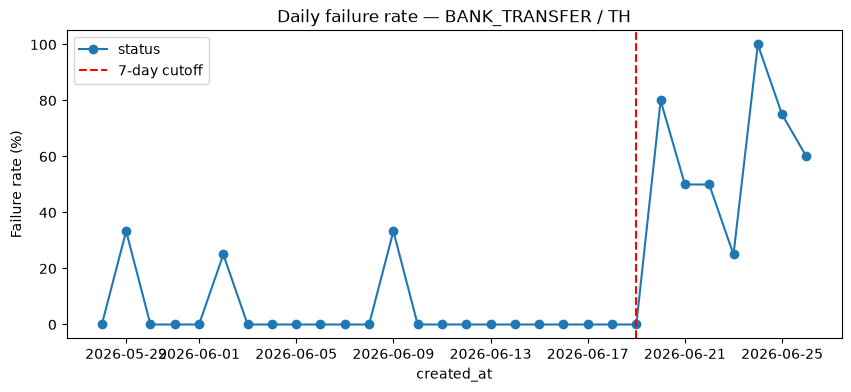

In [47]:
worst_channel, worst_region = comparison['rate_change'].idxmax()
print(f"Largest rate increase: {worst_channel} / {worst_region}")

subset = df[(df['channel'] == worst_channel) & (df['region'] == worst_region)]
daily_rate = subset.groupby(subset['created_at'].dt.date)['status'].apply(lambda s: (s == 'FAILED').mean() * 100)

plt.figure(figsize=(10, 4))
daily_rate.plot(marker='o')
plt.axvline(cutoff.date(), color='red', linestyle='--', label='7-day cutoff')
plt.ylabel('Failure rate (%)')
plt.title(f'Daily failure rate — {worst_channel} / {worst_region}')
plt.legend()
plt.show()

## Step 15 — Summarize findings and recommend (template)

**Why:** A case isn't finished when the chart looks right — it's finished when you can state, in plain language, what you found, where, since when, and what should happen next. Fill this in as plain text/markdown, the same way you'd say it out loud to an interviewer.

> **What I found:** *(e.g., the overall failure rate looks stable, but one channel/region combination shows a sharp recent increase)*
>
> **Where it's concentrated:** *(channel + region, from Step 13)*
>
> **When it started:** *(the cutoff date, from the chart in Step 14)*
>
> **Likely cause (hypothesis, not certainty):** *(tie to `status_reason` — e.g. NETWORK_ERROR dominance in that slice)*
>
> **Recommended next step:** *(e.g., escalate to the payment provider for that channel/region, check for a recent integration or routing change)*
>
> **Guardrail KPI to track after a fix:** *(e.g., daily failure rate for that channel/region, watched for the next 2 weeks)*

---
## Quick-reference checklist (for the live test itself)

When you're under time pressure and can't re-derive all of this from scratch, run this mental list in order:

1. Shape, head, tail, dtypes — do I know what I'm holding?
2. Nulls — where, how many?
3. Duplicates — full-row, and on whatever should be a unique key
4. Fix dtypes — dates to datetime, repeat-text to category
5. Consistency — `nunique()` on text columns, eyeball samples for formatting noise
6. Range sanity — `describe()`, impossible values, unexpected category labels
7. Clean — explicit decisions, flag over silently dropping where you can
8. **Sort before anything time-based** — the single most common silent bug
9. Separate into the subsets the business question actually needs
10. Group by one dimension, then by combined dimensions — don't stop at one
11. Rate, not raw count, whenever comparing groups of different sizes
12. Recent window vs. baseline, when the question is "did something change"
13. Visualize only after you know which slice to look at
14. State the finding, the location, the timing, and the recommendation — out loud, every time, even if no one's listening yet